# Bimodal: synthesis with a fixed $\Theta_{\rm reg}(t)$ (open loop) vs MGD (closed loop)

Job **150794** (2026-11-13, H100 dev), script `lam_selection_criterion/bimodal_openloop.py`. Plots only: reads the three
`results/bimodal_openloop/beta_*/openloop_run000.pt` files, computes nothing new.

**Setup.** Density $p^*(x) \propto \exp(\beta x/2 + 5\beta x^2 - \beta x^4)$, potentials $\phi = (x, x^2/2, x^3/3, x^4/4)$,
$\beta \in \{0.1, 0.9, 1.9\}$, $N = 10^6$ walkers, $n_t = 5\cdot10^4$ (two-phase grid), $\sigma = 10$. One dataset, $\Theta_{\rm reg}$ from seed 0.

* **Closed loop (MGD):** at every step the corrector solves $\theta_k$ from the current walkers.
* **Open loop (option B1):** the corrector uses the stored curve $\Theta_{\rm reg}(t_{k+1})$ (linear interpolation in $t$), no solve.
  The **predictor still solves $\eta_k$ from the walkers** (only $\theta$ is prescribed). Synthesis noise seed 777000 (different from the run that produced $\Theta$).

Candidates for $\Theta_{\rm reg}$ (all from the same closed-loop run, seed 0):

| | weights | $\lambda$ |
|---|---|---|
| C0 | uniform | 0 (= raw $\theta_t$ of the run, up to float32 rounding) |
| C1 | uniform | cross-seed CV on $t \ge 0.99$ — **current rule** (10-06) |
| C3 | Guth et al. 2025 eq. 8 weights mapped to the Cos schedule | 1 (Guth adds the two terms with weight 1) |

C3: the weights equal Guth's exactly (re-derived 11-16), but his time-score term is a derivative at fixed noisy point $y = I/\sin\alpha$,
ours at fixed $I$: same weights, not exactly the same time loss (difference = a term in the space-score error; effect not measured).
Two more candidates (C2: $\Sigma$-metric cross-seed $\lambda$; C4: oracle $\lambda$) are in the files but not shown.

**$z$-score.** For each statistic $a$: $z_a = (\hat m_a - m_a)/\mathrm{SE}_a$, $\hat m_a$ = walker mean of $\phi_a$, $\mathrm{SE}_a$ = its standard error
($\mathrm{std}/\sqrt N$). Target $m_a$: at the end, the mean over the $10^6$ data $x_1$; along $t$, the empirical moment of the interpolant
$\cos(\alpha_t) x_0 + \sin(\alpha_t) x_1$. For independent exact samples of $p^*$, the end-time $z_a \sim \mathcal N(0, 2)$ (both means noisy, same variance):
95 % band $|z| < 1.96\sqrt2 \approx 2.8$. Along $t$ there is no such reference (the target shares $x_0$ with the walkers), so no band is drawn there.

**Limits.** One seed, one dataset. Walkers were not saved: no histograms. $\max|x|$ only at its peak (open loop) or at $t=1$ (closed loop).

In [1]:
from pathlib import Path
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

ROOT = Path.cwd()
while not (ROOT / 'lam_selection_criterion').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RES = ROOT / 'lam_selection_criterion' / 'results' / 'bimodal_openloop'
BETAS = (0.1, 0.9, 1.9)
D = {b: torch.load(RES / f'beta_{b:.2f}' / 'openloop_run000.pt', map_location='cpu', weights_only=False) for b in BETAS}

CANDS = ['C0_lam0', 'C1_uniform_xseed_end0.99', 'C3_guth_lam1']   # C2 (Σ x-seed) and C4 (oracle) are in the .pt, not shown
SHORT = {'baseline': 'MGD closed loop', 'check_ii_C0_same_seed': 'C0, same noise as MGD',
         'C0_lam0': 'C0 λ=0', 'C1_uniform_xseed_end0.99': 'C1 x-seed (current)',
         'C2_uniform_xseed_sigma_end0.99': 'C2 Σ x-seed (new)', 'C3_guth_lam1': 'C3 Guth λ=1',
         'C4_uniform_oracle_end': 'C4 oracle λ'}
COLOR = {'baseline': 'k', 'check_ii_C0_same_seed': '0.6', 'C0_lam0': 'tab:blue', 'C1_uniform_xseed_end0.99': 'tab:orange',
         'C2_uniform_xseed_sigma_end0.99': 'tab:green', 'C3_guth_lam1': 'tab:red', 'C4_uniform_oracle_end': 'tab:purple'}
STAT = ['x', 'x²/2', 'x³/3', 'x⁴/4']


def theta_star(beta):
    # code sign, log p* = theta* . phi + const (bimodal_lamtest.py:136)
    return np.array([beta / 2, 10 * beta, 0.0, -4 * beta])


def get(d, name):
    return d['baseline'][0] if name == 'baseline' else d['results'][name]


def lam_label(lam):
    return '0' if lam == 0 else f'{lam:g}'


def distinct(d):
    # candidates actually run (a candidate with 'same_as' reuses another one's Theta and walkers)
    return [c for c in CANDS if 'same_as' not in d['results'][c]]


for b in BETAS:
    d = D[b]
    print(f"beta {b}: " + ', '.join(f"{SHORT[c].split()[0]} λ={lam_label(d['candidates'][c]['lam'])}"
                                     + (f" (= {SHORT[d['results'][c]['same_as']]})" if 'same_as' in d['results'][c] else '')
                                     for c in CANDS))

beta 0.1: C0 λ=0, C1 λ=0.001, C3 λ=1
beta 0.9: C0 λ=0, C1 λ=0.0001, C3 λ=1
beta 1.9: C0 λ=0, C1 λ=1e-05, C3 λ=1


## 1. Divergences: summary table

`peak max|x|/max|x1|`: largest $|x|$ over all walkers and steps, divided by the largest $|x|$ of the data (open loop; closed loop: at $t=1$ only).
`diverged` = non-finite walkers (rule agreed 11-13: no threshold).

In [2]:
rows = []
for b in BETAS:
    d = D[b]
    for name in ['baseline', 'check_ii_C0_same_seed'] + CANDS:
        r = get(d, name)
        rows.append({'β': b, 'run': SHORT[name], 'λ': r.get('lam', np.nan), 'same as': SHORT.get(r.get('same_as'), ''),
                     'diverged': r['diverged'], 't diverged': r['diverged_t'],
                     'peak max|x|/max|x1|': r['maxabs_ratio_peak'], 't of peak': r['t_of_peak'],
                     'end max|z|': r['end_max_abs_z'], 'end rms z': r['end_rms_z'],
                     'end max|δ| [% std]': r['end_max_abs_z'] * 100 / np.sqrt(int(d['args']['n1'])),
                     'P(x<0)': r['small_well'], 'P(x<0) true': r['small_well_true'],
                     'KL(p*||p_Θ(1)) [nats]': r.get('kl_theta_end', np.nan)})
tab = pd.DataFrame(rows)
with pd.option_context('display.max_rows', 50, 'display.width', 250):
    display(tab.style.format({'λ': '{:g}', 't diverged': '{:.4f}', 'peak max|x|/max|x1|': '{:.3g}', 't of peak': '{:.3f}',
                              'end max|z|': '{:.3g}', 'end rms z': '{:.3g}', 'end max|δ| [% std]': '{:.3g}', 'P(x<0)': '{:.4f}', 'P(x<0) true': '{:.4f}',
                              'KL(p*||p_Θ(1)) [nats]': '{:.3g}'}, na_rep='—').hide(axis='index'))

for b in BETAS:
    r = D[b]['results']['check_ii_C0_same_seed']
    print(f"beta {b}: same-noise check, final walkers vs closed loop: max |dx| = {r['vs_closed_max_abs']:.3g} "
          f"(relative to max|x| of closed loop: {r['vs_closed_max_rel']:.3g})")

β,run,λ,same as,diverged,t diverged,peak max|x|/max|x1|,t of peak,end max|z|,end rms z,end max|δ| [% std],P(x<0),P(x<0) true,KL(p*||p_Θ(1)) [nats]
0.100000,MGD closed loop,—,,False,—,0.973,—,0.000243,0.000138,2.43e-05,0.4670,0.4675,—
0.100000,"C0, same noise as MGD",0,,False,—,1.71,0.090,0.000242,0.000138,2.42e-05,0.4670,0.4675,2.26
0.100000,C0 λ=0,0,,False,—,1.73,0.008,1.94,1.36,0.194,0.4667,0.4675,2.26
0.100000,C1 x-seed (current),0.001,,False,—,1.69,0.008,1.62,1.15,0.162,0.4665,0.4675,3.92e-06
0.100000,C3 Guth λ=1,1,,False,—,1.71,0.008,9.96,5.9,0.996,0.4670,0.4675,0.00012
0.900000,MGD closed loop,—,,False,—,1,—,0.000496,0.000296,4.96e-05,0.2041,0.2040,—
0.900000,"C0, same noise as MGD",0,,False,—,2.51,0.090,0.000496,0.000297,4.96e-05,0.2041,0.2040,17.5
0.900000,C0 λ=0,0,,False,—,2.54,0.206,0.935,0.631,0.0935,0.2045,0.2040,17.5
0.900000,C1 x-seed (current),0.0001,,False,—,2.52,0.206,0.567,0.435,0.0567,0.2045,0.2040,1.45e-06
0.900000,C3 Guth λ=1,1,,False,—,2.51,0.206,14,9.65,1.4,0.2098,0.2040,0.000603


beta 0.1: same-noise check, final walkers vs closed loop: max |dx| = 0.000185 (relative to max|x| of closed loop: 5.18e-05)
beta 0.9: same-noise check, final walkers vs closed loop: max |dx| = 0.00116 (relative to max|x| of closed loop: 0.000459)
beta 1.9: same-noise check, final walkers vs closed loop: max |dx| = 3.1 (relative to max|x| of closed loop: 1.36)


## 2. The prescribed curves $\Theta_{\rm reg}(t)$

Code sign: the corrector moves walkers along $h\sigma^2\nabla(\Theta\cdot\phi)$. C0 ($\lambda=0$) is the closed-loop $\theta_t$ itself
(max relative difference $2.6\cdot10^{-7}$, smoke 150030), so the gap between C0 and the other curves is what the regularisation removes.
Stars at $t=1$: the true $\theta^*$ (only $\Theta(1)$ should reach it). Vertical dotted lines: divergence time of the open-loop run with that colour.
Left: whole transport ($t$ linear). Right: end of the transport ($1-t$ on a log axis, time runs left to right).

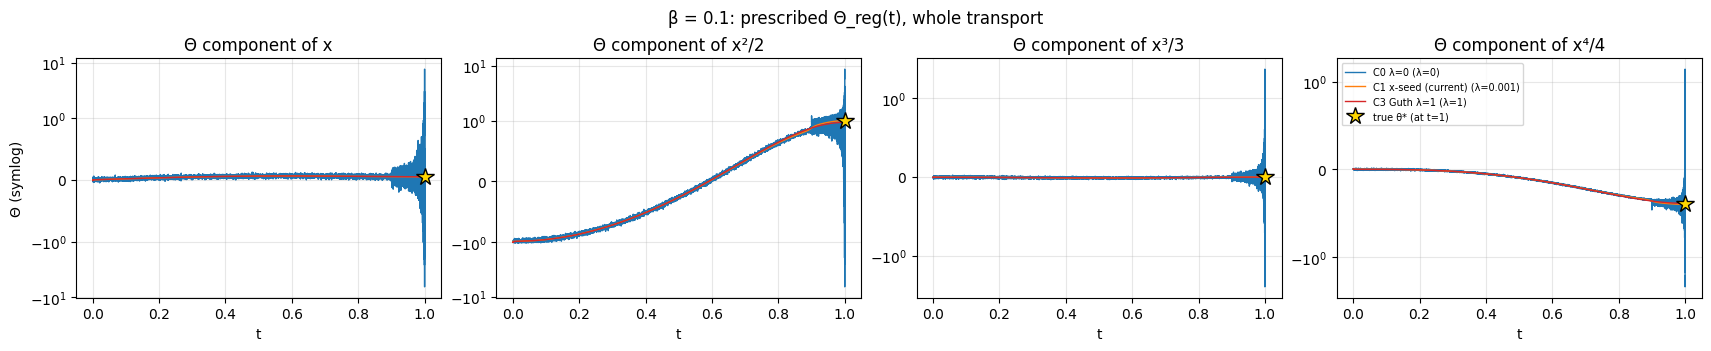

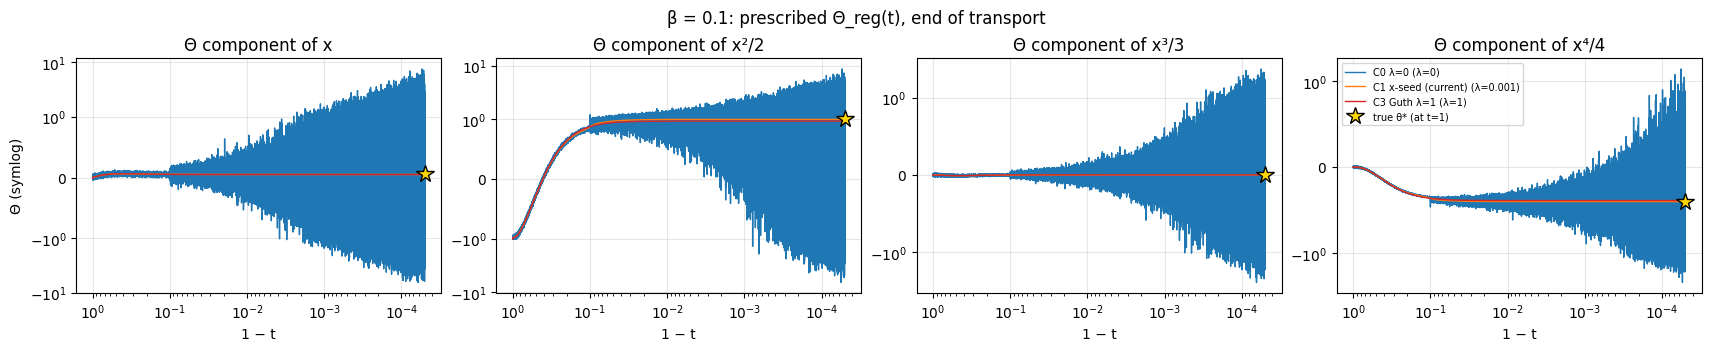

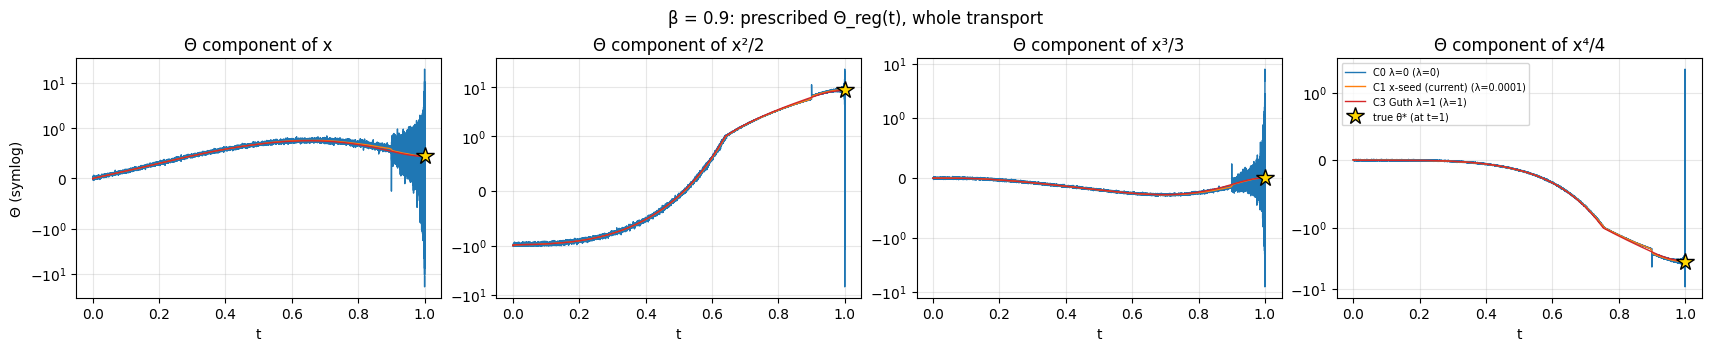

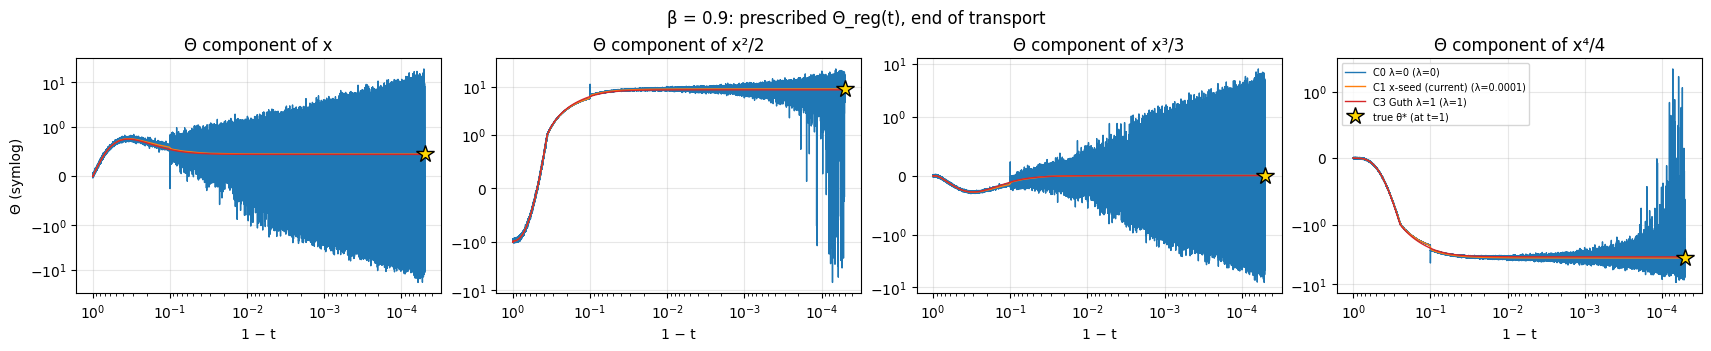

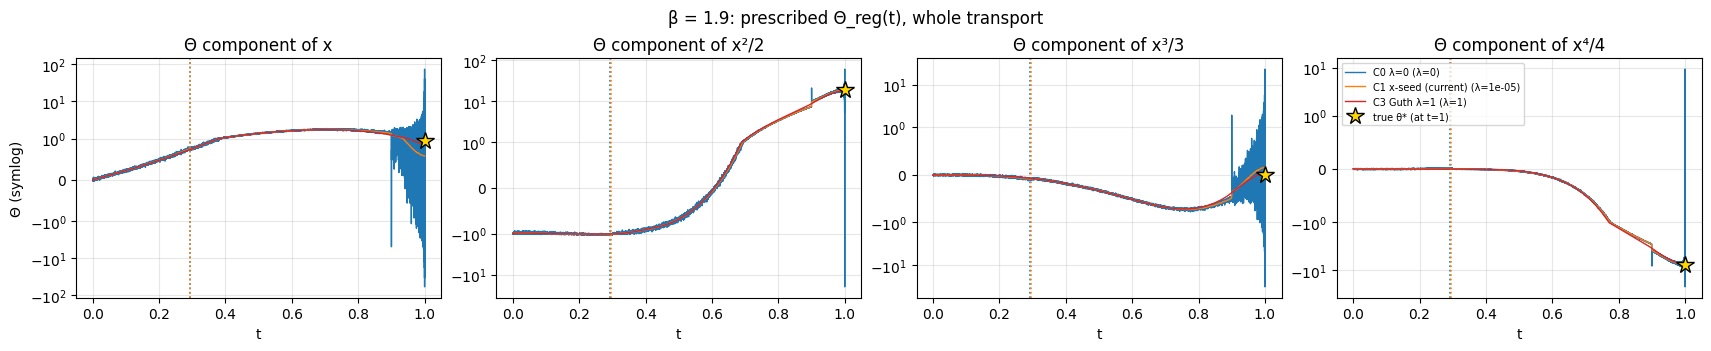

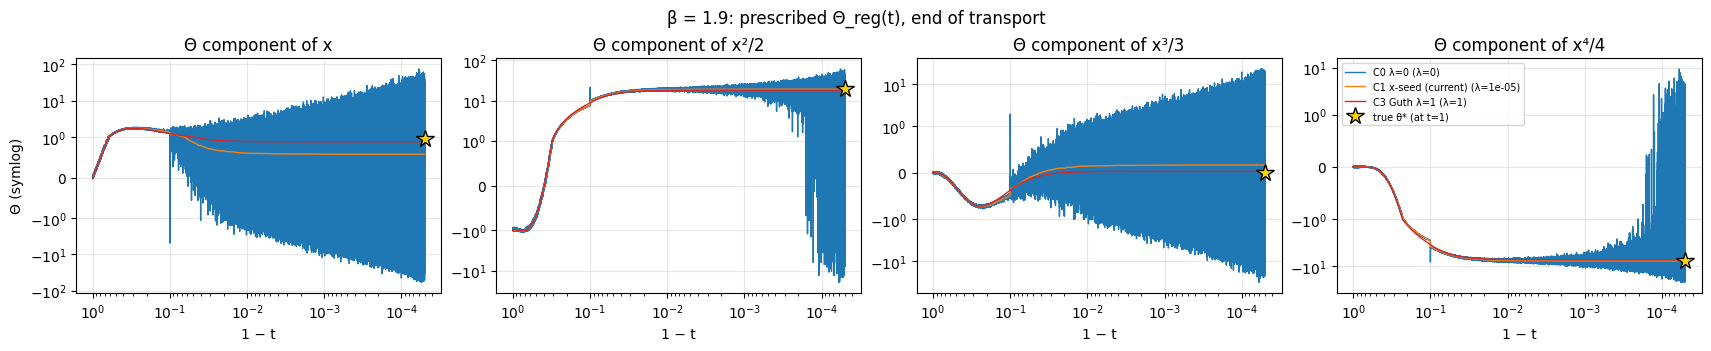

In [3]:
def theta_plot(b, xmode):
    d = D[b]
    t = np.asarray(d['t_sys'])
    fig, axs = plt.subplots(1, 4, figsize=(17, 3.4), constrained_layout=True)
    for name in distinct(d):
        c = d['candidates'][name]
        Th = d['theta_seed0'][f"{c['sched']}|{lam_label(c['lam'])}"].double().numpy()
        r = d['results'][name]
        for a, ax in enumerate(axs):
            x = t if xmode == 'lin' else 1 - t
            ax.plot(x, Th[:, a], color=COLOR[name], lw=1, label=f"{SHORT[name]} (λ={lam_label(c['lam'])})")
            if r['diverged'] and xmode == 'lin':
                ax.axvline(r['diverged_t'], color=COLOR[name], ls=':', lw=1.2)
    ts = theta_star(b)
    for a, ax in enumerate(axs):
        ax.plot(1.0 if xmode == 'lin' else 1 - t[-1], ts[a], marker='*', ms=13, color='gold',
                mec='k', ls='none', label='true θ* (at t=1)', zorder=5)
        ax.set_title(f'Θ component of {STAT[a]}')
        ax.set_yscale('symlog', linthresh=1.0)
        if xmode == 'lin':
            ax.set_xlabel('t')
        else:
            ax.set_xscale('log'); ax.invert_xaxis(); ax.set_xlabel('1 − t')
        ax.grid(alpha=0.3)
    axs[0].set_ylabel('Θ (symlog)')
    axs[-1].legend(fontsize=7, loc='best')
    fig.suptitle(f'β = {b}: prescribed Θ_reg(t), ' + ('whole transport' if xmode == 'lin' else 'end of transport'))
    plt.show()


for b in BETAS:
    theta_plot(b, 'lin')
    theta_plot(b, 'log')

## 3. Quality along the transport: $\delta_a(t)$, open loop vs MGD

**Plotted: the absolute size of the error**, $\delta_a = (\hat m_a - m_a)/\mathrm{std}(\phi_a)$ in % — the error of the walkers' mean in units of the
spread of the statistic across walkers. It does not depend on $N$. Computed from the stored $z$: $\delta = z/\sqrt N$ exactly (SE $= \mathrm{std}/\sqrt N$).
Dotted lines: one standard error of the mean, $1/\sqrt N = 0.1\,\%$ ($N = 10^6$), the size of pure statistical noise.
Closed loop: std from the run's stored covariance $\Sigma(t)$; open loop: std of the walkers. Curves stop where a run diverged.

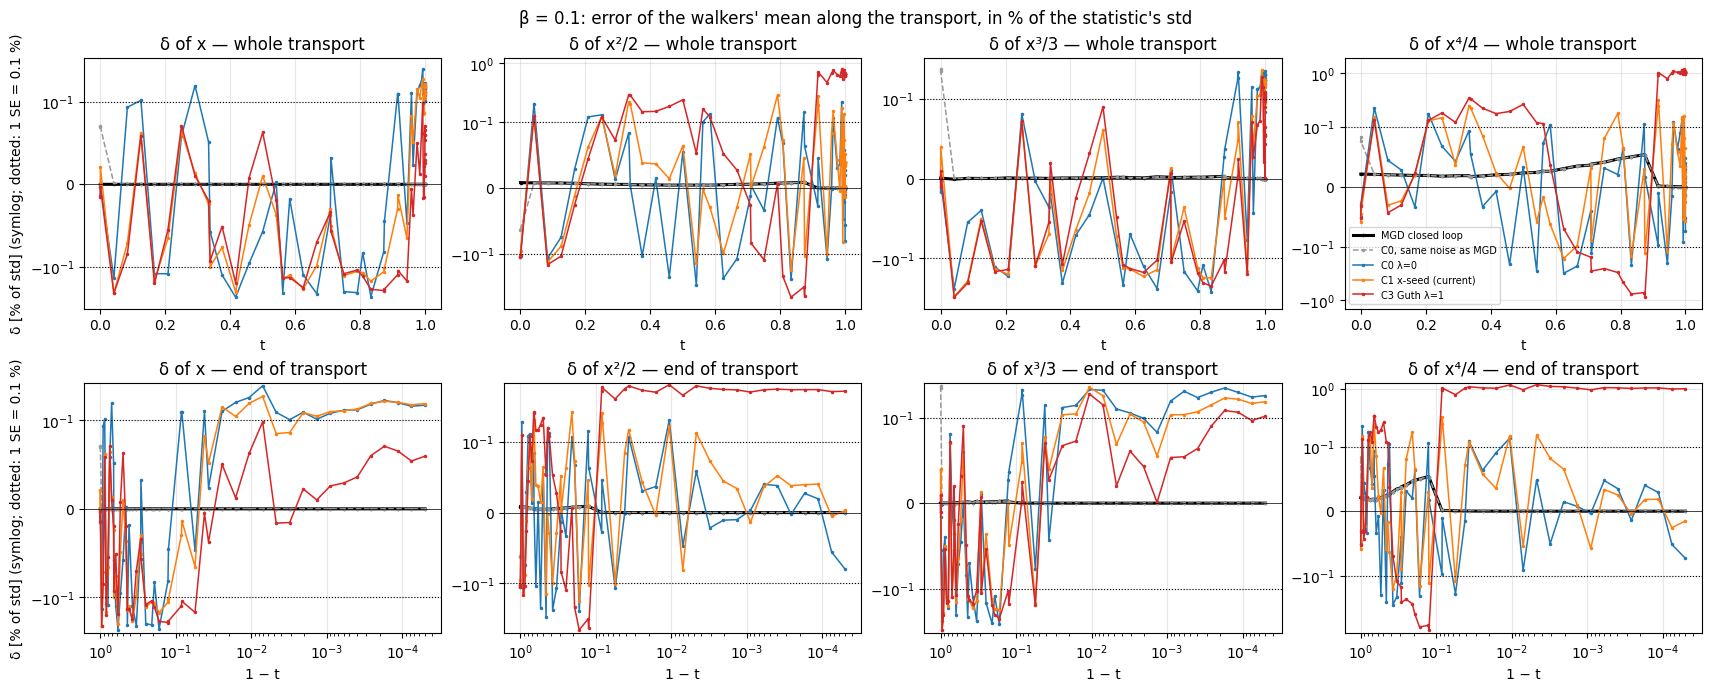

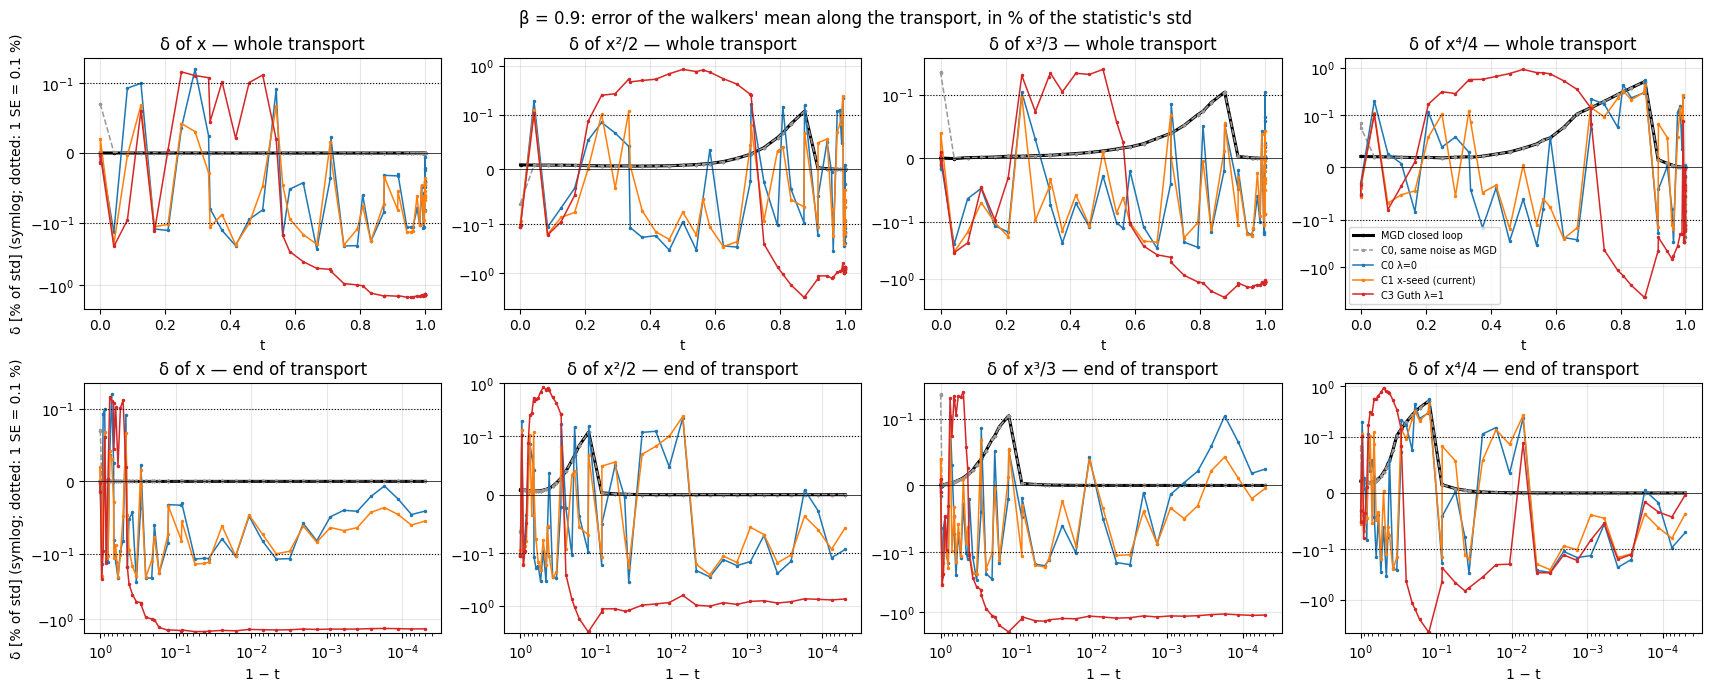

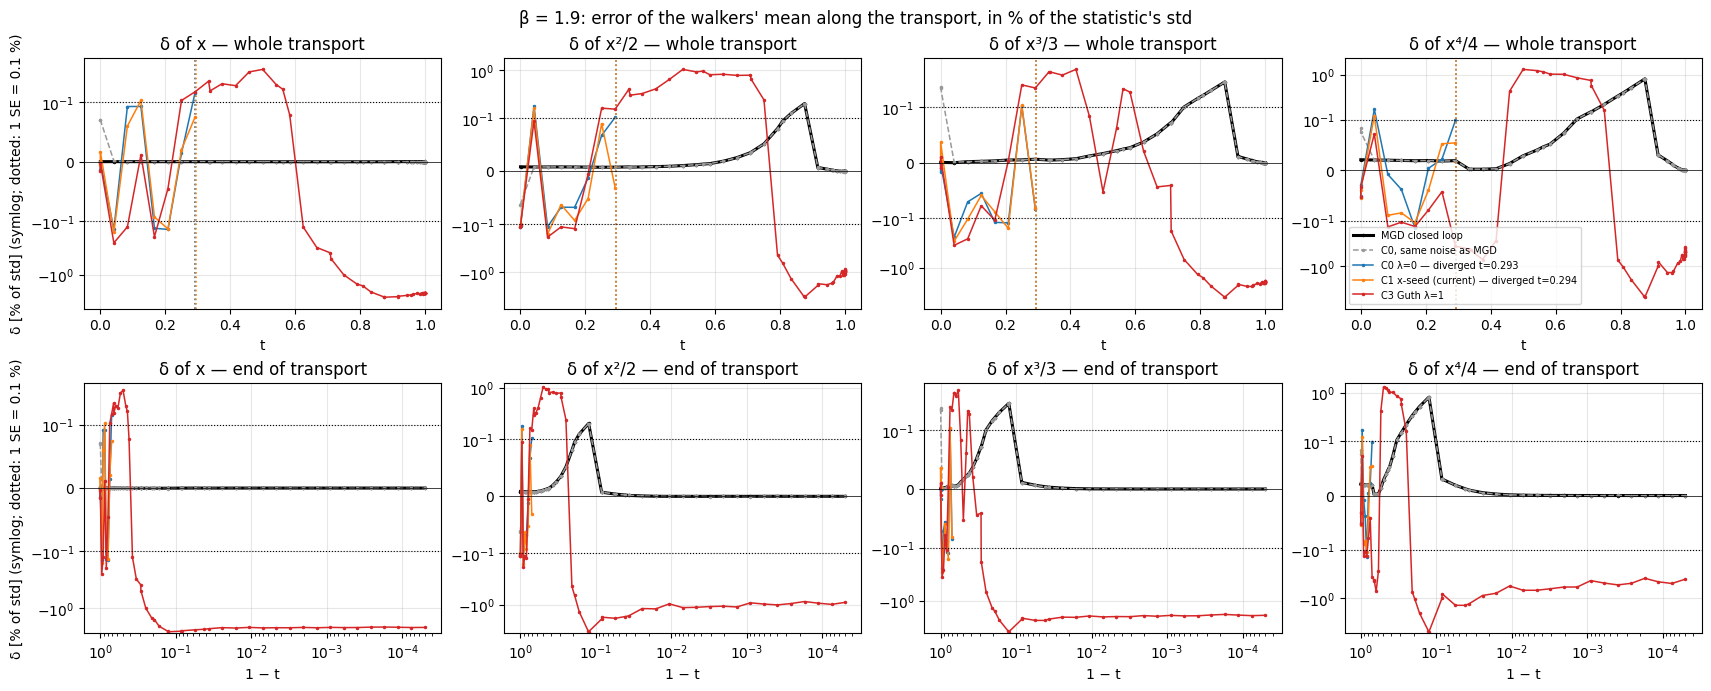

In [4]:
def z_plot(b):
    # row 0: t linear (whole transport, where beta 1.9 diverges); row 1: 1 - t log (end of the transport)
    d = D[b]
    N = int(d['args']['n1'])
    se_pct = 100 / np.sqrt(N)
    fig, axs = plt.subplots(2, 4, figsize=(17, 6.8), constrained_layout=True)
    for name in ['baseline', 'check_ii_C0_same_seed'] + distinct(d):
        r = get(d, name)
        tt = np.asarray(r['along']['t']); z = np.asarray(r['along']['z']) * se_pct   # delta in % of std
        ls = '--' if name == 'check_ii_C0_same_seed' else '-'
        lw = 2.2 if name == 'baseline' else 1.1
        lab = SHORT[name] + (f" — diverged t={r['diverged_t']:.3f}" if r['diverged'] else '')
        for a in range(4):
            axs[0, a].plot(tt, z[:, a], ls, color=COLOR[name], lw=lw, marker='.', ms=3, label=lab)
            axs[1, a].plot(1 - tt, z[:, a], ls, color=COLOR[name], lw=lw, marker='.', ms=3, label=lab)
            if r['diverged']:
                axs[0, a].axvline(r['diverged_t'], color=COLOR[name], ls=':', lw=1.2)
    for row in range(2):
        for a in range(4):
            ax = axs[row, a]
            if row == 0:
                ax.set_xlabel('t')
            else:
                ax.set_xscale('log'); ax.invert_xaxis(); ax.set_xlabel('1 − t')
            ax.set_yscale('symlog', linthresh=se_pct)
            for s in (-1, 1):
                ax.axhline(s * se_pct, color='k', ls=':', lw=0.8)
            ax.axhline(0, color='k', lw=0.5)
            ax.set_title(f'δ of {STAT[a]}' + (' — whole transport' if row == 0 else ' — end of transport'))
            ax.grid(alpha=0.3)
        axs[row, 0].set_ylabel(f'δ [% of std] (symlog; dotted: 1 SE = {se_pct:.2g} %)')
    axs[0, -1].legend(fontsize=7, loc='best')
    fig.suptitle(f'β = {b}: error of the walkers\' mean along the transport, in % of the statistic\'s std')
    plt.show()


for b in BETAS:
    z_plot(b)

## 4. Quality at the end: $\delta_a(t=1)$ and the small-well mass

$\delta_a$ = (walker mean − data mean) / std, in %. Grey band: $|\delta| < 1.96\sqrt{2/N} \approx 0.28\,\%$, the 95 % range for
**independent exact samples** of $p^*$ (both means noisy: $z \sim \mathcal N(0,2)$).
The closed loop sits far inside it by construction (it forces its moments onto the data's). Diverged runs have no bar.
Right: fraction of walkers with $x<0$; band = truth $\pm 2$ binomial standard errors $\sqrt{p(1-p)/N}$ (the spread of an exact sampler).

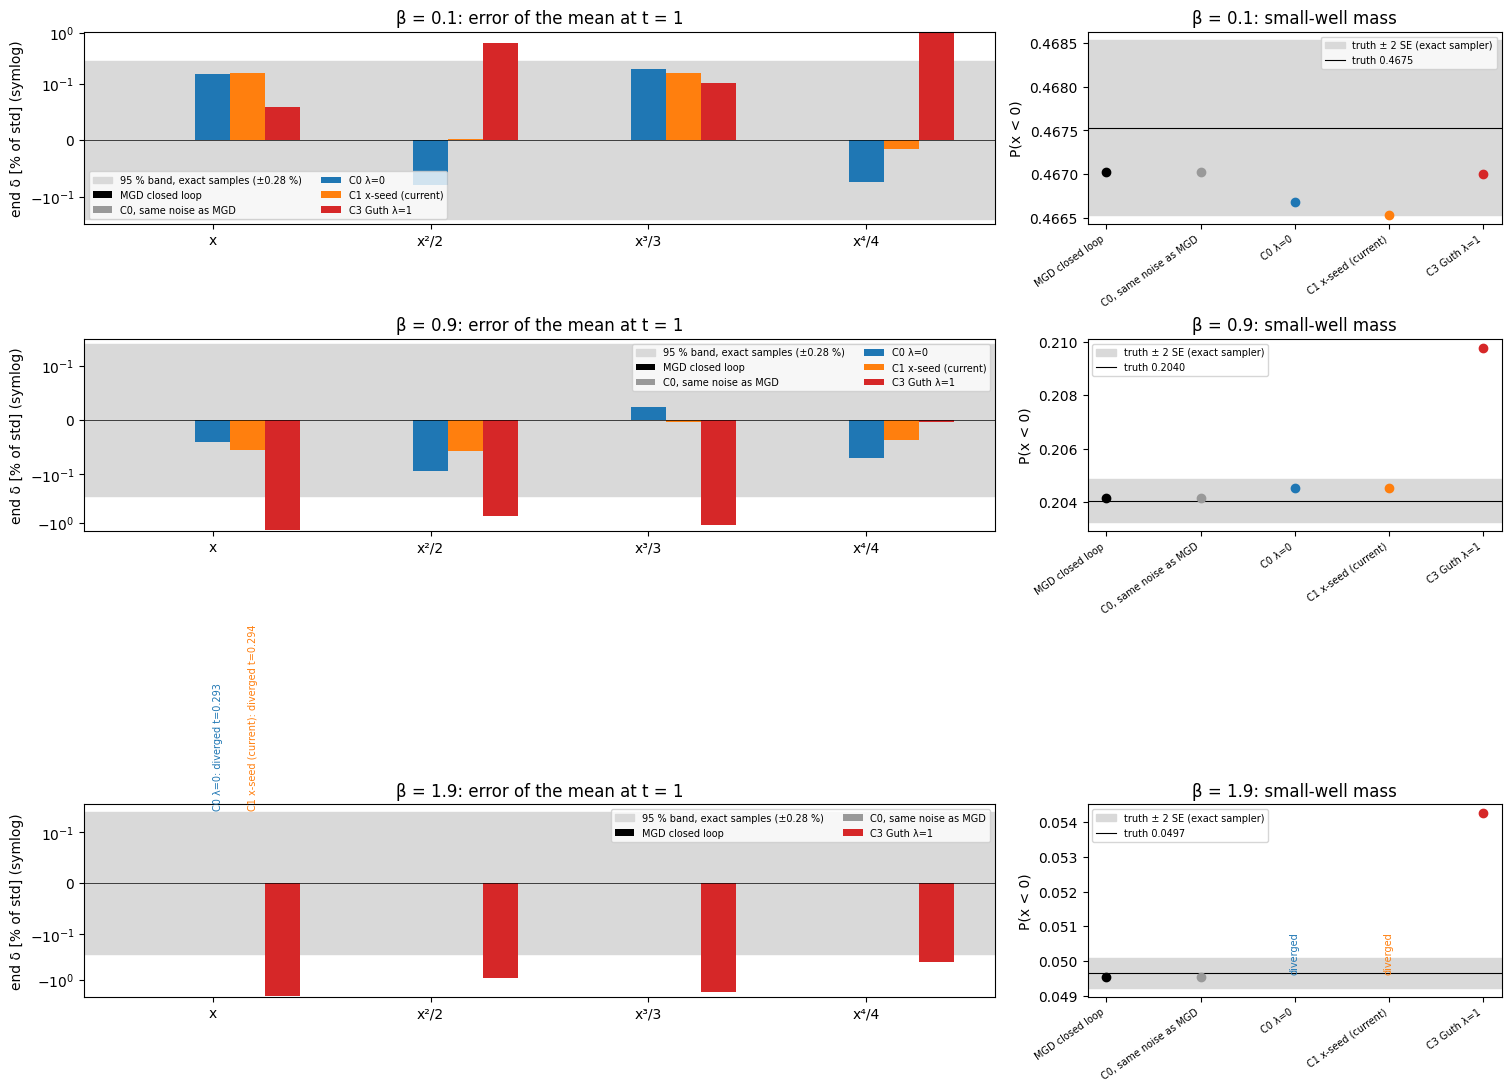

In [5]:
fig, axs = plt.subplots(len(BETAS), 2, figsize=(15, 3.6 * len(BETAS)), constrained_layout=True,
                        gridspec_kw={'width_ratios': [2.2, 1]})
for i, b in enumerate(BETAS):
    d = D[b]
    names = ['baseline', 'check_ii_C0_same_seed'] + distinct(d)
    ax = axs[i, 0]
    w = 0.8 / len(names)
    se_pct = 100 / np.sqrt(int(d['args']['n1']))
    band = 1.96 * np.sqrt(2) * se_pct
    ax.axhspan(-band, band, color='0.85', label=f'95 % band, exact samples (±{band:.2f} %)')
    for j, name in enumerate(names):
        r = get(d, name)
        x = np.arange(4) + (j - (len(names) - 1) / 2) * w
        if r['end_z'] is None:
            ax.text(x[0], 0.3, f"{SHORT[name]}: diverged t={r['diverged_t']:.3f}", rotation=90, fontsize=7,
                    color=COLOR[name], va='bottom')
            continue
        ax.bar(x, np.asarray(r['end_z']) * se_pct, w, color=COLOR[name], label=SHORT[name])
    ax.set_xticks(range(4)); ax.set_xticklabels(STAT)
    ax.set_yscale('symlog', linthresh=se_pct); ax.axhline(0, color='k', lw=0.5)
    ax.set_ylabel('end δ [% of std] (symlog)'); ax.set_title(f'β = {b}: error of the mean at t = 1')
    ax.legend(fontsize=7, ncol=2)

    ax = axs[i, 1]
    p = get(d, 'baseline')['small_well_true']; n = int(d['args']['n1'])
    se = np.sqrt(p * (1 - p) / n)
    ax.axhspan(p - 2 * se, p + 2 * se, color='0.85', label='truth ± 2 SE (exact sampler)')
    ax.axhline(p, color='k', lw=0.8, label=f'truth {p:.4f}')
    for j, name in enumerate(names):
        r = get(d, name)
        if np.isfinite(r['small_well']):
            ax.plot(j, r['small_well'], 'o', color=COLOR[name])
        else:
            ax.text(j, p, 'diverged', rotation=90, fontsize=7, color=COLOR[name], ha='center')
    ax.set_xticks(range(len(names))); ax.set_xticklabels([SHORT[n_] for n_ in names], rotation=35, ha='right', fontsize=7)
    ax.set_ylabel('P(x < 0)'); ax.set_title(f'β = {b}: small-well mass'); ax.legend(fontsize=7)
plt.show()

## 5. Final model $p_{\Theta(1)}$: exact KL to $p^*$ (no synthesis involved)

$\mathrm{KL}(p^*\,\|\,p_{\Theta(1)})$ by quadrature on $[-10, 10]$, for every $\lambda$ of the grid, seed 0. This needs only the closed-loop run
and the regularised solve, not the open-loop synthesis. Report it only with up-to-date $\Theta_{\rm reg}$: C1 is the current rule;
C2 is unvalidated and the Guth mapping (C3) is unchecked. $\lambda=0$ is drawn at the left end of the axis.

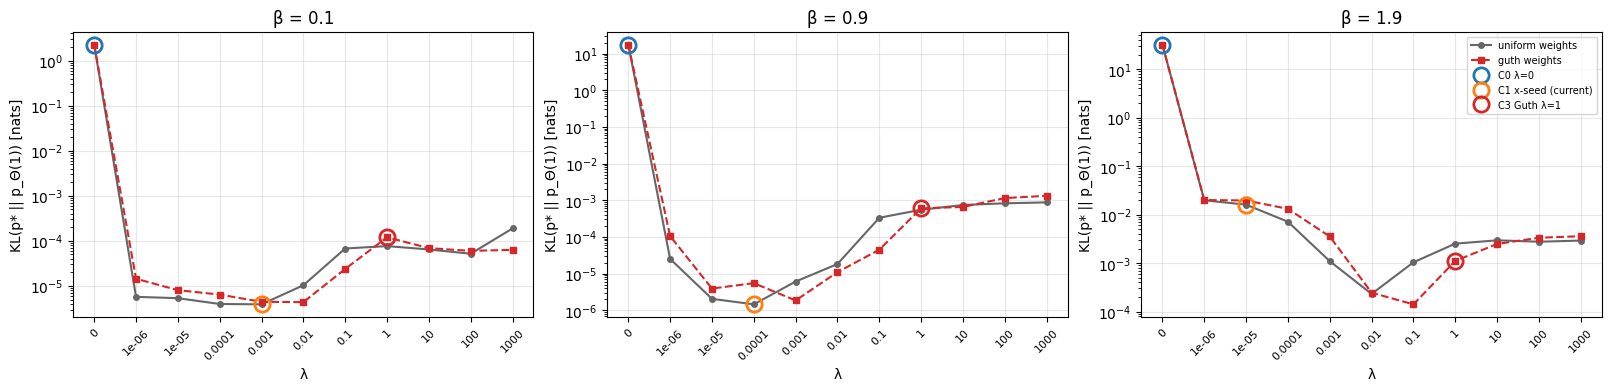

In [6]:
fig, axs = plt.subplots(1, len(BETAS), figsize=(16, 3.8), constrained_layout=True)
for ax, b in zip(axs, BETAS):
    d = D[b]
    lams = np.asarray(d['lams'], dtype=float)
    pos = np.arange(len(lams))
    for sched, ls in (('uniform', '-o'), ('guth', '--s')):
        kl = np.asarray(d['kl_end_seed0'][sched], dtype=float)
        ax.plot(pos, kl, ls, color='0.4' if sched == 'uniform' else 'tab:red', ms=4, label=f'{sched} weights')
    for name in distinct(d):
        c = d['candidates'][name]
        k = int(np.argmin(np.abs(lams - c['lam'])))
        kl = d['kl_end_seed0'][c['sched']][k]
        ax.plot(pos[k], kl, 'o', ms=11, mfc='none', mew=2, color=COLOR[name], label=f"{SHORT[name]}")
    ax.set_xticks(pos); ax.set_xticklabels([lam_label(l) for l in lams], rotation=45, fontsize=8)
    ax.set_yscale('log'); ax.set_xlabel('λ'); ax.set_ylabel('KL(p* || p_Θ(1)) [nats]')
    ax.set_title(f'β = {b}'); ax.grid(alpha=0.3)
axs[-1].legend(fontsize=7)
plt.show()